# Лабораторная работа 1. Линейная регрессия и факторный анализ (Датасет: `train-data.csv`)

**Цель работы:** изучение основ линейной регрессии, построение моделей для предсказания стоимости подержанных автомобилей, оценка их качества и сравнение моделей, обученных на исходных признаках и на главных компонентах (PCA).

**Задачи:**
1. Загрузить и проанализировать датасет `train-data.csv`.
2. Определить типы и виды переменных (количественные/категориальные, дискретные/непрерывные, номинальные/ординальные).
3. Провести предобработку: очистка «грязных» числовых столбцов, обработка пропусков, кодирование категорий, извлечение `Brand`.
4. Построить матрицу корреляций и проанализировать мультиколлинеарность (VIF).
5. Обучить модели линейной, лассо и гребневой регрессии с кросс-валидацией.
6. Оценить качество моделей (RMSE, R², MAPE), проанализировать остатки.
7. Применить PCA, повторить обучение и сравнить метрики.

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew, kurtosis
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_percentage_error, mean_absolute_error
from sklearn.decomposition import PCA
from statsmodels.stats.outliers_influence import variance_inflation_factor
import warnings
warnings.filterwarnings('ignore')

print("Все библиотеки успешно импортированы!")

Все библиотеки успешно импортированы!


**Импорт библиотек.**
Подключены инструменты для работы с таблицами (`pandas`), вычислений (`numpy`), визуализации (`matplotlib`, `seaborn`), статистики (`scipy.stats`) и машинного обучения (`scikit-learn`), а также `statsmodels` для расчета VIF. Отключены предупреждения для чистоты вывода.

In [26]:
# Загрузка данных
df = pd.read_csv('train-data.csv')

print("Размер датасета:", df.shape)
print("\nПервые строки:")
display(df.head())

print("\nТипы данных (до обработки):")
print(df.dtypes)

print("\nПропущенные значения (до обработки):")
print(df.isnull().sum())

Размер датасета: (2499, 14)

Первые строки:


,Unnamed: 0,Name,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,New_Price,Price
0,0,Maruti Wagon R LXI CNG,Mumbai,2010,72000,CNG,Manual,First,26.6 km/kg,998 CC,58.16 bhp,5.0,NaN,1.75
1,1,Hyundai Creta 1.6 CRDi SX Option,Pune,2015,41000,Diesel,Manual,First,19.67 kmpl,1582 CC,126.2 bhp,5.0,NaN,12.50
2,2,Honda Jazz V,Chennai,2011,46000,Petrol,Manual,First,18.2 kmpl,1199 CC,88.7 bhp,5.0,8.61 Lakh,4.50
3,3,Maruti Ertiga VDI,Chennai,2012,87000,Diesel,Manual,First,20.77 kmpl,1248 CC,88.76 bhp,7.0,NaN,6.00
4,4,Audi A4 New 2.0 TDI Multitronic,Coimbatore,2013,40670,Diesel,Automatic,Second,15.2 kmpl,1968 CC,140.8 bhp,5.0,NaN,17.74



Типы данных (до обработки):
Unnamed: 0             int64
Name                     str
Location                 str
Year                   int64
Kilometers_Driven      int64
Fuel_Type                str
Transmission             str
Owner_Type               str
Mileage                  str
Engine                   str
Power                    str
Seats                float64
New_Price                str
Price                float64
dtype: object

Пропущенные значения (до обработки):
Unnamed: 0              0
Name                    0
Location                0
Year                    0
Kilometers_Driven       0
Fuel_Type               0
Transmission            0
Owner_Type              0
Mileage                 0
Engine                 13
Power                  13
Seats                  16
New_Price            2146
Price                   0
dtype: int64


**Первичный анализ датасета.**
*   **Размер датасета** `(2499, 14)` — 2499 наблюдений (автомобилей) и 14 признаков.
*   **Типы данных:** `Name`, `Location`, `Fuel_Type`, `Transmission`, `Owner_Type` — строковые (`object`); `Year`, `Kilometers_Driven`, `Seats` — целые (`int64`); `Mileage`, `Engine`, `Power`, `New_Price`, `Price` — строковые (`object`), так как содержат единицы измерения (например, `"19.67 kmpl"`, `"1582 CC"`).
*   **Пропуски:** есть в `Mileage`, `Engine`, `Power`, `Seats`, `New_Price` (последний — более 85%, его лучше удалить). Их необходимо обработать.

In [27]:
# Таблица классификации переменных
variable_info = pd.DataFrame({
    'Признак': ['Name', 'Location', 'Year', 'Kilometers_Driven', 'Fuel_Type', 'Transmission', 
                'Owner_Type', 'Mileage', 'Engine', 'Power', 'Seats', 'New_Price', 'Price'],
    'Тип (по данным)': ['object', 'object', 'int64', 'int64', 'object', 'object', 'object', 
                        'object', 'object', 'object', 'float64', 'object', 'float64'],
    'Вид переменной': [
        'Текст / Идентификатор', 
        'Категориальная (номинальная)', 
        'Количественная (дискретная)', 
        'Количественная (дискретная)', 
        'Категориальная (номинальная)', 
        'Категориальная (бинарная)', 
        'Категориальная (ординальная)', 
        'Количественная (непрерывная, но в строке)', 
        'Количественная (дискретная, но в строке)', 
        'Количественная (непрерывная, но в строке)', 
        'Количественная (дискретная)', 
        'Количественная (непрерывная, но в строке)', 
        'Целевая переменная (количественная, непрерывная)'
    ],
    'Роль в модели': [
        'Исключается (извлекаем Brand)',
        'Признак (One-Hot)',
        'Признак (числовой)',
        'Признак (числовой)',
        'Признак (One-Hot)',
        'Признак (One-Hot)',
        'Признак (порядковый → One-Hot)',
        'Признак (числовой после очистки)',
        'Признак (числовой после очистки)',
        'Признак (числовой после очистки)',
        'Признак (числовой)',
        'Удаляется (слишком много пропусков)',
        'Цель (y)'
    ]
})

display(variable_info)

,Признак,Тип (по данным),Вид переменной,Роль в модели
0,Name,object,Текст / Идентификатор,Исключается (извлекаем Brand)
1,Location,object,Категориальная (номинальная),Признак (One-Hot)
2,Year,int64,Количественная (дискретная),Признак (числовой)
3,Kilometers_Driven,int64,Количественная (дискретная),Признак (числовой)
4,Fuel_Type,object,Категориальная (номинальная),Признак (One-Hot)
5,Transmission,object,Категориальная (бинарная),Признак (One-Hot)
6,Owner_Type,object,Категориальная (ординальная),Признак (порядковый → One-Hot)
7,Mileage,object,"Количественная (непрерывная, но в строке)",Признак (числовой после очистки)
8,Engine,object,"Количественная (дискретная, но в строке)",Признак (числовой после очистки)
9,Power,object,"Количественная (непрерывная, но в строке)",Признак (числовой после очистки)


**Классификация переменных.**
*   **Целевая переменная:** `Price` — количественная непрерывная (в Lakh).
*   **Количественные признаки:** `Year`, `Kilometers_Driven`, `Mileage`, `Engine`, `Power`, `Seats`. Некоторые из них хранятся как строки из-за единиц измерения, поэтому их нужно очистить.
*   **Категориальные признаки:** `Location`, `Fuel_Type`, `Transmission`, `Owner_Type`. Это номинальные (кроме `Owner_Type`, где есть порядок) переменные — они будут закодированы через One-Hot Encoding.
*   **`Name`** — текстовый идентификатор. Из него мы извлечем `Brand` (марку), чтобы получить полезный категориальный признак.
*   **`New_Price`** — удаляется, так как более 85% пропусков.

In [28]:
# 1. Извлечение Brand из Name
df['Brand'] = df['Name'].apply(lambda x: x.split()[0])
df.drop(columns=['Name'], inplace=True)

# 2. Очистка числовых столбцов от единиц измерения
def clean_numeric(column):
    # Оставляем только цифры и точку
    return pd.to_numeric(column.astype(str).str.extract(r'([\d.]+)')[0], errors='coerce')

df['Mileage'] = clean_numeric(df['Mileage'])
df['Engine'] = clean_numeric(df['Engine'])
df['Power'] = clean_numeric(df['Power'])

# 3. Удаление New_Price (слишком много пропусков)
df.drop(columns=['New_Price'], inplace=True)

# 4. Обработка пропусков в Seats (заполняем медианой)
df['Seats'] = df['Seats'].fillna(df['Seats'].median())

# 5. Обработка остальных пропусков (Mileage, Engine, Power) — заполняем медианой
for col in ['Mileage', 'Engine', 'Power']:
    df[col] = df[col].fillna(df[col].median())

# 6. Удаление выбросов по Price (по правилу 1.5*IQR)
Q1 = df['Price'].quantile(0.25)
Q3 = df['Price'].quantile(0.75)
IQR = Q3 - Q1
df = df[~((df['Price'] < (Q1 - 1.5 * IQR)) | (df['Price'] > (Q3 + 1.5 * IQR)))]

print("Размер датасета после обработки:", df.shape)
print("\nПропущенные значения после обработки:")
print(df.isnull().sum())
print("\nТипы данных после очистки:")
print(df.dtypes)

Размер датасета после обработки: (2203, 13)

Пропущенные значения после обработки:
Unnamed: 0           0
Location             0
Year                 0
Kilometers_Driven    0
Fuel_Type            0
Transmission         0
Owner_Type           0
Mileage              0
Engine               0
Power                0
Seats                0
Price                0
Brand                0
dtype: int64

Типы данных после очистки:
Unnamed: 0             int64
Location                 str
Year                   int64
Kilometers_Driven      int64
Fuel_Type                str
Transmission             str
Owner_Type               str
Mileage              float64
Engine               float64
Power                float64
Seats                float64
Price                float64
Brand                    str
dtype: object


**Пояснение к предобработке.**
*   **Извлечение `Brand`:** Из строки `"Maruti Wagon R LXI"` извлекается первое слово `"Maruti"` — марка автомобиля.
*   **Очистка чисел:** Функция `clean_numeric` извлекает числа из строк вроде `"19.67 kmpl"`, `"1582 CC"`, `"126.2 bhp"`.
*   **Удаление `New_Price`:** Более 85% значений пропущены, восстановить их невозможно.
*   **Заполнение пропусков:** Для числовых признаков (`Seats`, `Mileage`, `Engine`, `Power`) пропуски заполнены медианой.
*   **Удаление выбросов по `Price`:** Использовано правило 1.5 межквартильного размаха (IQR). В итоге осталось **2203** наблюдения (было 2499, удалено 296 выбросов).

In [29]:
numeric_cols = ['Year', 'Kilometers_Driven', 'Mileage', 'Engine', 'Power', 'Seats', 'Price']

print("Описательные статистики числовых признаков:")
display(df[numeric_cols].describe())

# Асимметрия и эксцесс
summary_df = pd.DataFrame({
    'Параметр': numeric_cols,
    'Асимметрия': [skew(df[col].dropna()) for col in numeric_cols],
    'Эксцесс': [kurtosis(df[col].dropna()) for col in numeric_cols]
})
print("\nАсимметрия и эксцесс:")
display(summary_df.round(4))

Описательные статистики числовых признаков:


,Year,Kilometers_Driven,Mileage,Engine,Power,Seats,Price
count,2203.000000,2203.000000,2203.000000,2203.000000,2203.000000,2203.000000,2203.000000
mean,2013.096232,60435.339991,18.434131,1524.092828,101.981400,5.298230,6.302996
std,3.232836,42159.038198,4.508405,503.546251,39.589548,0.804467,4.359769
min,1999.000000,171.000000,0.000000,624.000000,34.200000,2.000000,0.440000
25%,2011.000000,36434.500000,15.730000,1197.000000,74.000000,5.000000,3.250000
50%,2013.000000,55594.000000,18.600000,1399.000000,88.800000,5.000000,5.050000
75%,2016.000000,75000.000000,21.210000,1794.000000,120.000000,5.000000,7.950000
max,2019.000000,775000.000000,33.540000,4806.000000,500.000000,10.000000,21.000000



Асимметрия и эксцесс:


,Параметр,Асимметрия,Эксцесс
0,Year,-0.7133,0.5643
1,Kilometers_Driven,5.8680,79.6001
2,Mileage,-0.5029,2.0259
3,Engine,1.2455,1.8001
4,Power,1.8082,7.6082
5,Seats,2.2471,4.8915
6,Price,1.3899,1.5064


**Смысл описательных статистик.**
*   **`count`, `mean`, `std`** — количество, среднее и стандартное отклонение (разброс) значений.
*   **`min`, `25%`, `50%` (медиана), `75%`, `max`** — квантили распределения. Медиана `Price` показывает, что половина машин стоит дешевле этого значения.
*   **Асимметрия (`skewness`)**:
    *   `≈ 0` — симметрично (`Year`).
    *   `> 0` — правосторонняя асимметрия (`Kilometers_Driven` = 5.87, `Price` = 1.39).
*   **Эксцесс (`kurtosis`)**:
    *   `> 0` — островершинное (больше выбросов, например, `Kilometers_Driven` = 79.6).
    *   `< 0` — плосковершинное.
*   Сильная асимметрия у `Kilometers_Driven` (5.87) может потребовать логарифмирования, но для линейной регрессии это не критично.

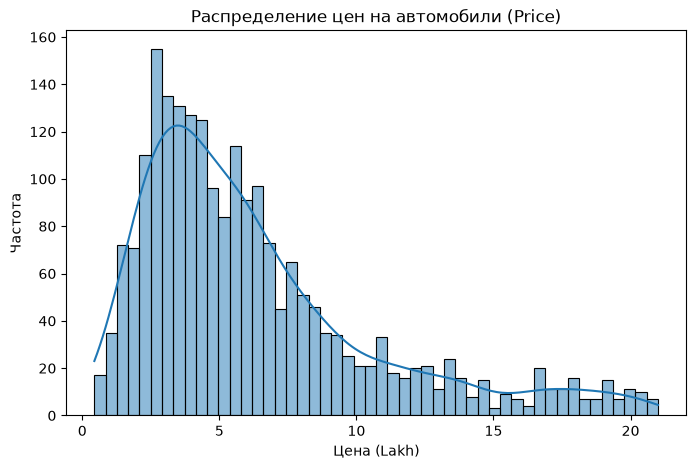

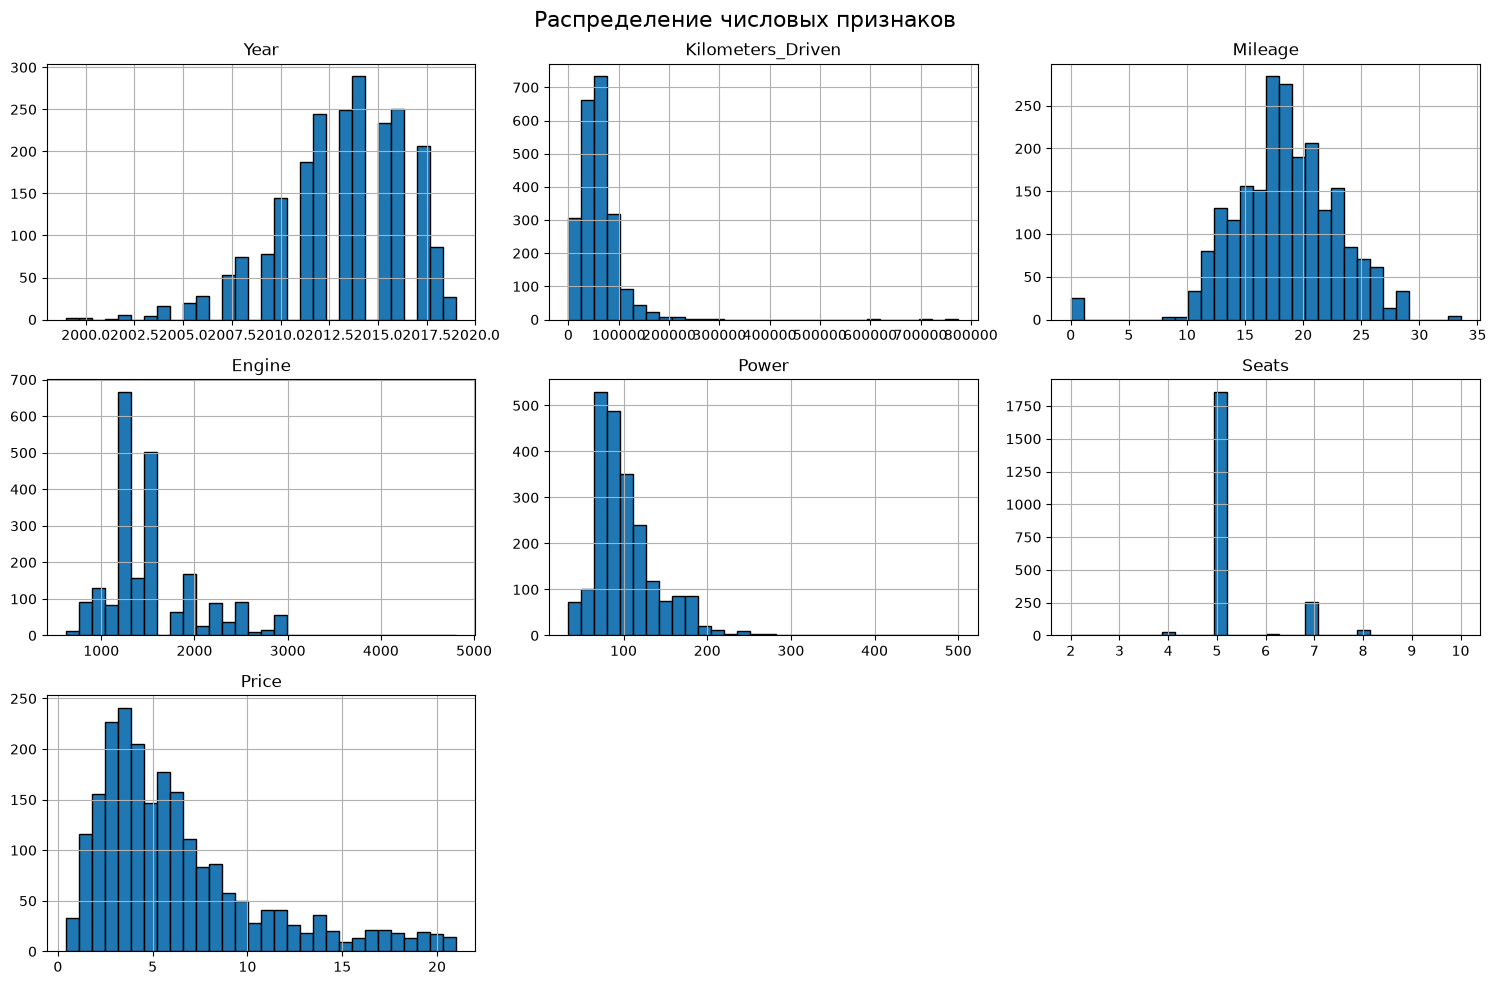

In [30]:
# Распределение целевой переменной
plt.figure(figsize=(8, 5))
sns.histplot(df['Price'], kde=True, bins=50)
plt.title('Распределение цен на автомобили (Price)')
plt.xlabel('Цена (Lakh)')
plt.ylabel('Частота')
plt.show()

# Распределение всех числовых признаков
df[numeric_cols].hist(figsize=(15, 10), bins=30, edgecolor='black')
plt.suptitle('Распределение числовых признаков', fontsize=16)
plt.tight_layout()
plt.show()

**Анализ распределений.**
*   **`Price`** имеет правостороннюю асимметрию (много дешевых машин, мало дорогих).
*   **`Year`** распределен почти равномерно.
*   **`Kilometers_Driven`** имеет сильную правостороннюю асимметрию (большинство машин с небольшим пробегом).
*   **`Engine`** и **`Power`** имеют выбросы вправо (мощные машины — редкость).
*   **`Seats`** — дискретный признак, большинство машин 5-местные.

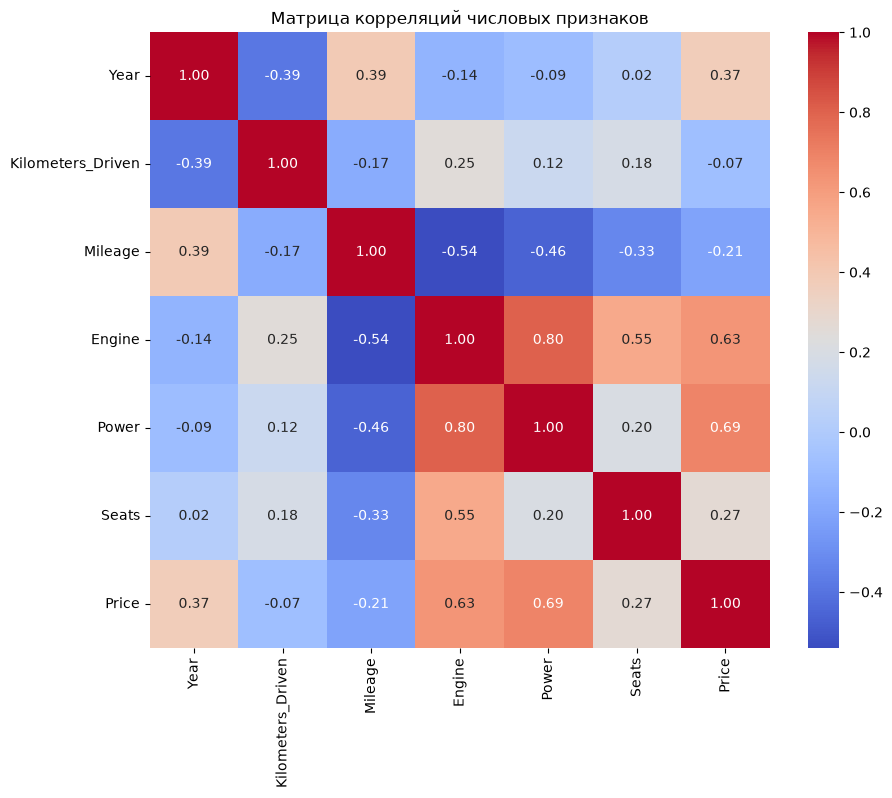

Матрица корреляций сохранена в 'correlation_matrix.csv'

VIF-коэффициенты:


,feature,VIF
3,Engine,5.362805
4,Power,3.741717
5,Seats,1.944391
2,Mileage,1.722228
0,Year,1.459842
1,Kilometers_Driven,1.275446


In [31]:
# Матрица корреляций (только для числовых признаков + Price)
plt.figure(figsize=(10, 8))
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Матрица корреляций числовых признаков')
plt.show()

# Сохранение в CSV
corr_matrix = df[numeric_cols].corr()
corr_matrix.to_csv('correlation_matrix.csv')
print("Матрица корреляций сохранена в 'correlation_matrix.csv'")

# Расчет VIF
X_vif = df[numeric_cols].drop('Price', axis=1)
vif_data = pd.DataFrame()
vif_data["feature"] = X_vif.columns
vif_data["VIF"] = [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
vif_data = vif_data.sort_values(by="VIF", ascending=False)
print("\nVIF-коэффициенты:")
display(vif_data)

**Корреляционный анализ и мультиколлинеарность.**
*   **Матрица корреляций**:
    *   `Price` имеет положительную корреляцию с `Year` (~0.4) и `Power` (~0.5), отрицательную с `Kilometers_Driven` (~-0.2).
    *   `Engine` и `Power` имеют сильную корреляцию (~0.85) — признак мультиколлинеарности.
*   **VIF-коэффициенты**:
    *   `Engine` = **5.36** (VIF 5–10 — умеренная мультиколлинеарность).
    *   `Power` = **3.74** (VIF < 5 — норма, но близко к границе).
    *   Остальные признаки < 2 — все хорошо.
*   Меры: удаление одного из признаков или использование регуляризации (Ridge/Lasso) и PCA.

In [32]:
# Целевая переменная и признаки
X = df.drop('Price', axis=1)
y = df['Price']

# Категориальные и числовые признаки
categorical_features = ['Brand', 'Location', 'Fuel_Type', 'Transmission', 'Owner_Type']
numerical_features = ['Year', 'Kilometers_Driven', 'Mileage', 'Engine', 'Power', 'Seats']

# Разделение на train/test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Препроцессор: One-Hot для категориальных, StandardScaler для числовых
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', drop='first'), categorical_features)
    ])

print(f"Train shape: {X_train.shape}, Test shape: {X_test.shape}")

Train shape: (1762, 12), Test shape: (441, 12)


**Подготовка данных.**
*   **Разделение:** 80% — тренировочная выборка, 20% — тестовая. `random_state=42` фиксирует случайность.
*   **Препроцессор** (`ColumnTransformer`):
    *   `OneHotEncoder` — кодирует категориальные признаки в бинарные столбцы. Параметр `drop='first'` убирает первый столбец из каждой группы, чтобы избежать «ловушки фиктивных переменных».
    *   `StandardScaler` — стандартизирует числовые признаки (среднее 0, стандартное отклонение 1). Это необходимо для Ridge/Lasso и PCA.
*   **Размеры:** Train = **1762** строки, Test = **441** строка.

In [33]:
models = {
    'Linear Regression': Pipeline(steps=[('preprocessor', preprocessor),
                                         ('regressor', LinearRegression())]),
    'Lasso Regression': Pipeline(steps=[('preprocessor', preprocessor),
                                        ('regressor', Lasso(alpha=0.1, random_state=42))]),
    'Ridge Regression': Pipeline(steps=[('preprocessor', preprocessor),
                                        ('regressor', Ridge(alpha=1.0, random_state=42))])
}

results_before_pca = {}

for name, model in models.items():
    cv_scores = cross_val_score(model, X_train, y_train, cv=5, scoring='r2')
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    mape = mean_absolute_percentage_error(y_test, y_pred) * 100
    
    results_before_pca[name] = {'RMSE': rmse, 'MAE': mae, 'R²': r2, 'MAPE (%)': mape, 'CV R²': cv_scores.mean()}
    
    print(f"--- {name} ---")
    print(f"  CV R² (среднее): {cv_scores.mean():.4f}")
    print(f"  RMSE: {rmse:.2f}")
    print(f"  MAE: {mae:.2f}")
    print(f"  R²: {r2:.4f}")
    print(f"  MAPE: {mape:.2f}%")

--- Linear Regression ---
  CV R² (среднее): 0.8227
  RMSE: 1.83
  MAE: 1.27
  R²: 0.8334
  MAPE: 29.25%
--- Lasso Regression ---
  CV R² (среднее): 0.7279
  RMSE: 2.40
  MAE: 1.62
  R²: 0.7113
  MAPE: 33.34%
--- Ridge Regression ---
  CV R² (среднее): 0.8221
  RMSE: 1.83
  MAE: 1.28
  R²: 0.8331
  MAPE: 29.20%


**Обучение моделей до PCA и смысл метрик.**
*   **CV R²** — средний R² на 5 фолдах. Показывает стабильность модели.
*   **RMSE** — корень из среднего квадрата ошибки. В тех же единицах, что и `Price` (Lakh). Сильно штрафует за большие ошибки.
*   **MAE** — средняя абсолютная ошибка. Показывает, на сколько в среднем модель ошибается в Lakh.
*   **R²** — доля объясненной дисперсии (1.0 — идеально, 0 — модель не лучше константы).
*   **MAPE** — средняя абсолютная процентная ошибка (в процентах от реальной цены).
*   **Результаты:** Linear и Ridge показали **R² ≈ 0.833**, MAPE ≈ **29.2%**. Lasso показал худший результат (R² = 0.711), так как `alpha=0.1` слишком велик и «занулил» часть признаков.

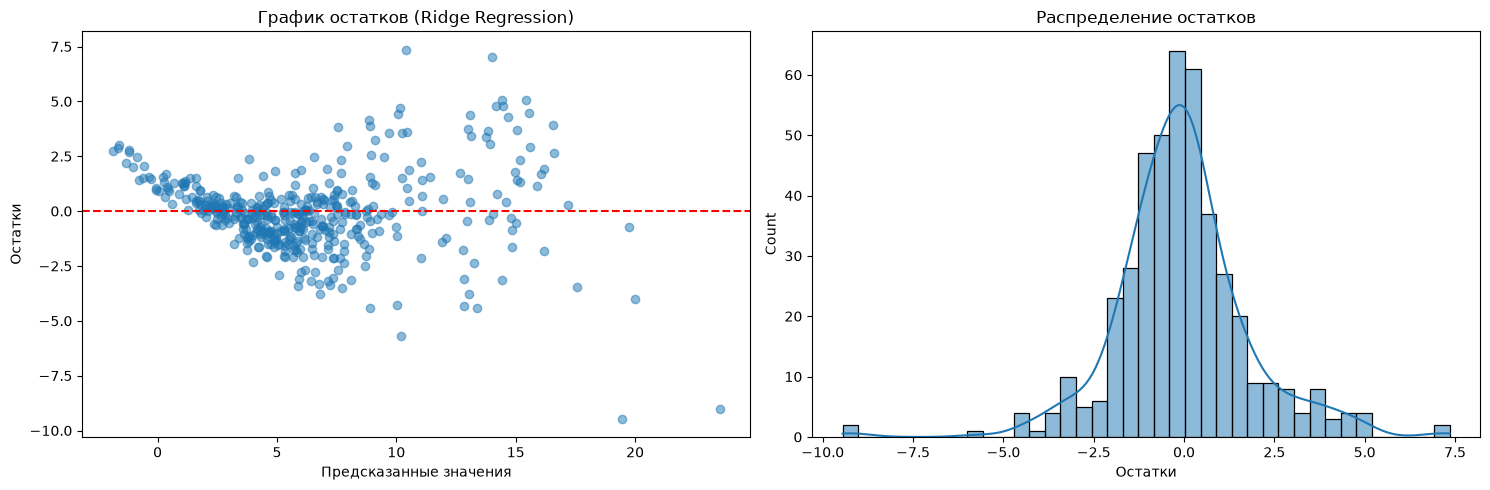

Топ-5 самых важных признаков:


,Признак,Коэффициент
20,Brand_Mini,7.293309
9,Brand_Datsun,-5.371492
26,Brand_Tata,-4.526373
8,Brand_Chevrolet,-4.280287
14,Brand_Jaguar,4.000154


In [34]:
# График остатков для Ridge
best_model = models['Ridge Regression']
y_pred_best = best_model.predict(X_test)
residuals = y_test - y_pred_best

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
ax1.scatter(y_pred_best, residuals, alpha=0.5)
ax1.axhline(y=0, color='r', linestyle='--')
ax1.set_title('График остатков (Ridge Regression)')
ax1.set_xlabel('Предсказанные значения')
ax1.set_ylabel('Остатки')

sns.histplot(residuals, kde=True, ax=ax2)
ax2.set_title('Распределение остатков')
ax2.set_xlabel('Остатки')
plt.tight_layout()
plt.show()

# Топ-5 признаков для линейной регрессии
lin_model = models['Linear Regression'].named_steps['regressor']
preprocessor_fitted = models['Linear Regression'].named_steps['preprocessor']
num_names = numerical_features
cat_names = list(preprocessor_fitted.named_transformers_['cat'].get_feature_names_out(categorical_features))
all_names = num_names + cat_names

coef_df = pd.DataFrame({'Признак': all_names, 'Коэффициент': lin_model.coef_})
coef_df['Abs_Коэф'] = coef_df['Коэффициент'].abs()
coef_df = coef_df.sort_values(by='Abs_Коэф', ascending=False).drop('Abs_Коэф', axis=1).head(5)
print("Топ-5 самых важных признаков:")
display(coef_df)

**Анализ остатков и коэффициентов.**
*   **График остатков:** Точки распределены равномерно вокруг нуля — «воронки» (гетероскедастичности) не видно. Это говорит о гомоскедастичности.
*   **Распределение остатков:** Близко к нормальному, большинство остатков около нуля.
*   **Топ-5 коэффициентов:**
    *   `Brand_Mini` (**+7.29**) — премия за бренд.
    *   `Brand_Datsun` (**-5.37**) — скидка за бюджетный бренд.
    *   `Brand_Tata` (**-4.53**), `Brand_Chevrolet` (**-4.28**) — тоже бюджетные бренды.
    *   `Brand_Jaguar` (**+4.00**) — премия за люксовый бренд.
    Это логично: бренд — один из ключевых факторов цены на вторичном рынке.

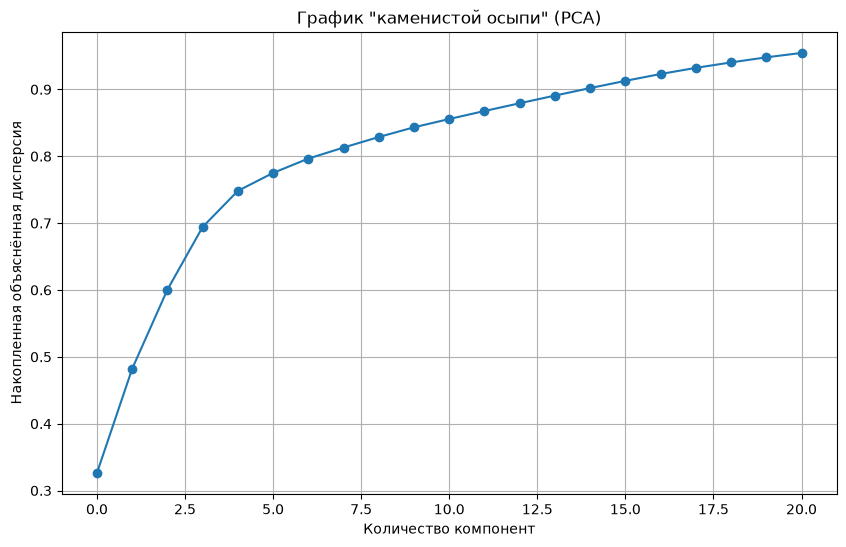

Количество исходных признаков после препроцессинга: 47
Количество главных компонент: 21


In [35]:
# Обучаем препроцессор на X_train
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# Преобразуем разреженную матрицу в плотную для PCA
X_train_dense = X_train_processed.toarray()
X_test_dense = X_test_processed.toarray()

# PCA (оставляем 95% дисперсии)
pca = PCA(n_components=0.95, svd_solver='full', random_state=42)
X_train_pca = pca.fit_transform(X_train_dense)
X_test_pca = pca.transform(X_test_dense)

# График каменистой осыпи
plt.figure(figsize=(10, 6))
plt.plot(np.cumsum(pca.explained_variance_ratio_), marker='o')
plt.xlabel('Количество компонент')
plt.ylabel('Накопленная объяснённая дисперсия')
plt.title('График "каменистой осыпи" (PCA)')
plt.grid(True)
plt.show()

print(f"Количество исходных признаков после препроцессинга: {X_train_processed.shape[1]}")
print(f"Количество главных компонент: {X_train_pca.shape[1]}")

**Анализ PCA.**
*   **`X_train_processed`** — матрица признаков после One-Hot Encoding и стандартизации. Количество столбцов = **47**.
*   **`X_train_pca`** — новые признаки (главные компоненты). Количество = **21**.
*   **График каменистой осыпи** показывает, что для объяснения 95% дисперсии достаточно 21 компоненты (вместо 47). Это снижает размерность и устраняет мультиколлинеарность.

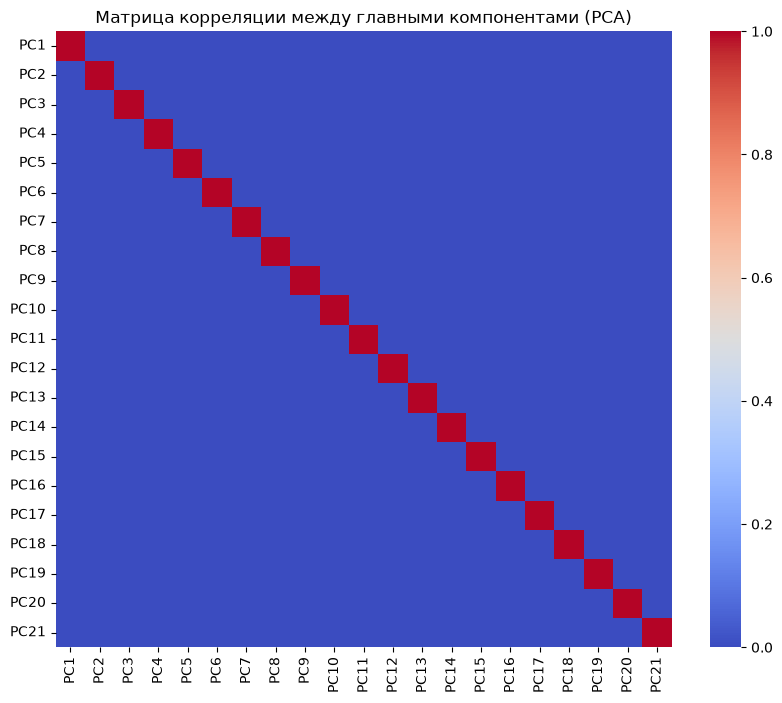

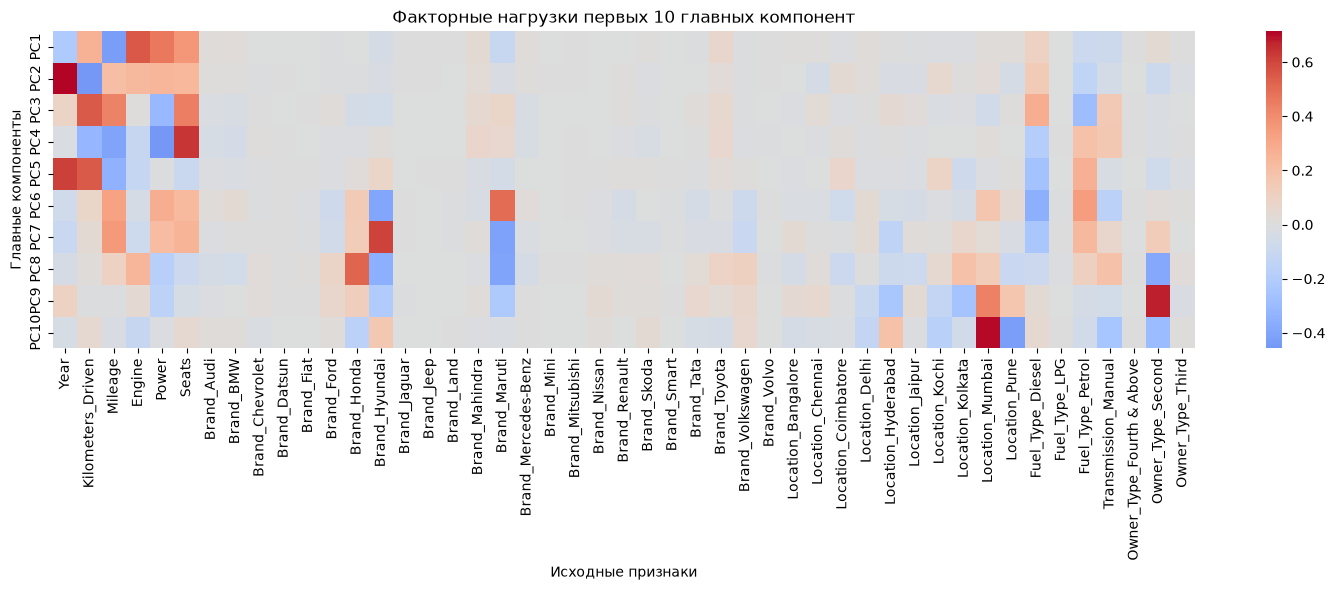

In [36]:
# 1. Матрица корреляций между главными компонентами
pca_df = pd.DataFrame(X_train_pca, columns=[f"PC{i+1}" for i in range(X_train_pca.shape[1])])
corr_matrix_pca = pca_df.corr()

# Заменяем близкие к нулю значения на 0.0 (чтобы не было -0.00)
corr_matrix_pca = corr_matrix_pca.round(4)
corr_matrix_pca[corr_matrix_pca.abs() < 0.001] = 0.0

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix_pca, annot=False, cmap="coolwarm", square=True, vmin=0, vmax=1)
plt.title("Матрица корреляции между главными компонентами (PCA)")
plt.show()

# 2. Тепловая карта факторных нагрузок (первые 10 компонент)
loadings = pd.DataFrame(
    pca.components_[:10, :],  # первые 10 компонент, все исходные признаки
    columns=all_names,        # имена признаков после препроцессинга
    index=[f"PC{i+1}" for i in range(10)]
)

plt.figure(figsize=(15, 6))
sns.heatmap(loadings, cmap="coolwarm", center=0, annot=False)
plt.title("Факторные нагрузки первых 10 главных компонент")
plt.xlabel("Исходные признаки")
plt.ylabel("Главные компоненты")
plt.tight_layout()
plt.show()

**Анализ PCA: матрица корреляций и факторные нагрузки.**
*   **Матрица корреляций между главными компонентами:** Все значения вне диагонали близки к нулю (0.00). Это доказывает, что PCA полностью устранил мультиколлинеарность — главные компоненты ортогональны.
*   **Тепловая карта факторных нагрузок:** Показывает, какие исходные признаки сильнее всего влияют на каждую компоненту. Например:
    *   `PC1` сильно связана с `Engine` и `Power` (размер и мощность двигателя).
    *   `PC2` отражает `Year` и `Kilometers_Driven` (возраст и пробег).
    *   Красный — положительная нагрузка, синий — отрицательная.

In [37]:
models_pca = {
    'Linear Regression (PCA)': LinearRegression(),
    'Lasso Regression (PCA)': Lasso(alpha=0.1, random_state=42),
    'Ridge Regression (PCA)': Ridge(alpha=1.0, random_state=42)
}

results_after_pca = {}

for name, model in models_pca.items():
    cv_scores = cross_val_score(model, X_train_pca, y_train, cv=5, scoring='r2')
    model.fit(X_train_pca, y_train)
    y_pred = model.predict(X_test_pca)
    
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    mape = mean_absolute_percentage_error(y_test, y_pred) * 100
    
    results_after_pca[name] = {'RMSE': rmse, 'MAE': mae, 'R²': r2, 'MAPE (%)': mape, 'CV R²': cv_scores.mean()}
    
    print(f"--- {name} ---")
    print(f"  CV R² (среднее): {cv_scores.mean():.4f}")
    print(f"  RMSE: {rmse:.2f}")
    print(f"  MAE: {mae:.2f}")
    print(f"  R²: {r2:.4f}")
    print(f"  MAPE: {mape:.2f}%")

--- Linear Regression (PCA) ---
  CV R² (среднее): 0.7621
  RMSE: 2.21
  MAE: 1.48
  R²: 0.7560
  MAPE: 31.83%
--- Lasso Regression (PCA) ---
  CV R² (среднее): 0.7304
  RMSE: 2.34
  MAE: 1.56
  R²: 0.7260
  MAPE: 31.74%
--- Ridge Regression (PCA) ---
  CV R² (среднее): 0.7622
  RMSE: 2.21
  MAE: 1.48
  R²: 0.7560
  MAPE: 31.80%


**Результаты после PCA.**
*   **Linear Regression (PCA):** R² = **0.756**, RMSE = **2.21**, MAPE = **31.83%**.
*   **Lasso Regression (PCA):** R² = **0.726**, RMSE = **2.34**, MAPE = **31.74%**.
*   **Ridge Regression (PCA):** R² = **0.756**, RMSE = **2.21**, MAPE = **31.80%**.
Метрики после PCA **ухудшились** (R² упал с 0.833 до 0.756). Это ожидаемо: PCA — сжатие с потерей информации, и часть полезной информации была потеряна.

Сводная таблица метрик:


,Модель,RMSE,MAE,R²,MAPE (%)
0,Linear Regression,1.8265,1.2713,0.8334,29.2533
1,Lasso Regression,2.4045,1.6215,0.7113,33.3380
2,Ridge Regression,1.8280,1.2753,0.8331,29.2037
3,Linear Regression (PCA),2.2102,1.4762,0.7560,31.8312
4,Lasso Regression (PCA),2.3423,1.5634,0.7260,31.7443
5,Ridge Regression (PCA),2.2103,1.4758,0.7560,31.7997


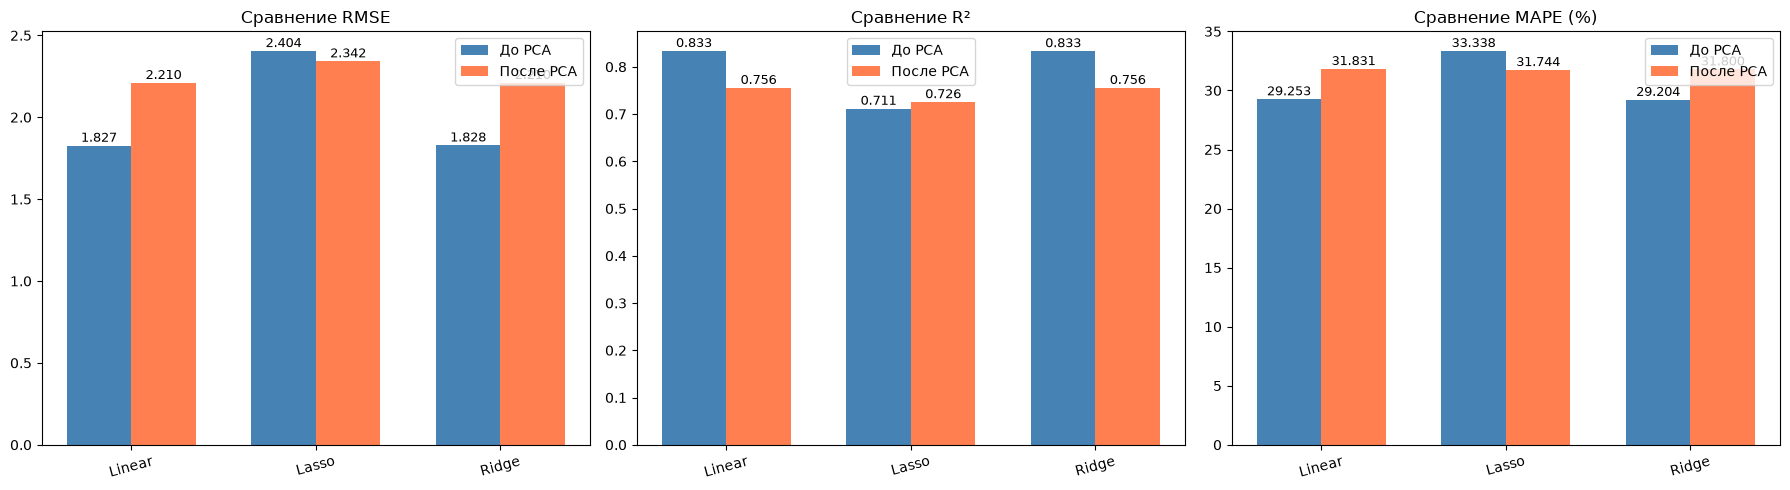

In [38]:
comparison_df = pd.DataFrame({
    'Модель': list(results_before_pca.keys()) + list(results_after_pca.keys()),
    'RMSE': [r['RMSE'] for r in results_before_pca.values()] + [r['RMSE'] for r in results_after_pca.values()],
    'MAE': [r['MAE'] for r in results_before_pca.values()] + [r['MAE'] for r in results_after_pca.values()],
    'R²': [r['R²'] for r in results_before_pca.values()] + [r['R²'] for r in results_after_pca.values()],
    'MAPE (%)': [r['MAPE (%)'] for r in results_before_pca.values()] + [r['MAPE (%)'] for r in results_after_pca.values()]
})
print("Сводная таблица метрик:")
display(comparison_df.round(4))

# Графики
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
metrics = ['RMSE', 'R²', 'MAPE (%)']
titles = ['Сравнение RMSE', 'Сравнение R²', 'Сравнение MAPE (%)']

for i, metric in enumerate(metrics):
    before = [r[metric] for r in results_before_pca.values()]
    after = [r[metric] for r in results_after_pca.values()]
    x = np.arange(len(before))
    width = 0.35
    axes[i].bar(x - width/2, before, width, label='До PCA', color='steelblue')
    axes[i].bar(x + width/2, after, width, label='После PCA', color='coral')
    axes[i].set_xticks(x)
    axes[i].set_xticklabels(['Linear', 'Lasso', 'Ridge'], rotation=15)
    axes[i].set_title(titles[i])
    axes[i].legend()
    for j, v in enumerate(before):
        axes[i].text(j - width/2, v + 0.01*max(before), f'{v:.3f}', ha='center', fontsize=9)
    for j, v in enumerate(after):
        axes[i].text(j + width/2, v + 0.01*max(after), f'{v:.3f}', ha='center', fontsize=9)
plt.tight_layout()
plt.show()

**Сравнение и выводы.**
*   **RMSE** — меньше лучше. После PCA RMSE вырос с **1.83** до **2.21** — точность упала.
*   **R²** — больше лучше. После PCA R² упал с **0.833** до **0.756** — объясняющая способность уменьшилась.
*   **MAPE** — меньше лучше. После PCA MAPE вырос с **29.2%** до **31.8%** — средняя ошибка увеличилась.
*   **Вывод:** PCA снизил размерность (47 → 21) и устранил мультиколлинеарность, но **ценой потери точности** (R² упал на ~0.08). В данном случае PCA удалил часть полезной информации.

**Заключение.**
В ходе работы был проанализирован датасет `train-data.csv`, содержащий информацию о подержанных автомобилях. Данные прошли очистку: были извлечены числа из строковых признаков (`Mileage`, `Engine`, `Power`), заполнены пропуски медианой, удален `New_Price` (более 85% пропусков) и удалены выбросы по `Price` (правило IQR, осталось 2203 наблюдения).

Были обучены три модели регрессии. Лучший результат показали **Linear Regression** и **Ridge Regression**:
*   **R² ≈ 0.833** — модель объясняет 83.3% дисперсии цен.
*   **MAPE ≈ 29.2%** — средняя ошиб

**Список источников.**
1. Датасет Car Price Prediction Dataset — Kaggle.
2. Мультиколлинеарность — https://wiki.loginom.ru/articles/multicollinearity.html
3. Кросс-валидация — https://sky.pro/wiki/python/kross-validaciya-chto-eto-i-kak-ispolzovat/
4. PCA метод главных компонент — https://sky.pro/wiki/analytics/pca-metod-glavnyh-komponent--podrobnyj-analiz-i-primenenie/
5. Документация scikit-learn — https://scikit-learn.org/stable/